# ДЗ2

Проверим два изменения — нелинейную MLP и сдвиги цифр на обучении.
Из ДЗ1 берём тот же split и логрег с accuracy 91,33%.
Основная метрика — accuracy, дополнительная — macro-F1.

У всех MLP один скрытый слой, 20 эпох и одинаковое число шагов.

In [1]:
import hashlib
import json
import os
import time
import tomllib
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss
from sklearn.neural_network import MLPClassifier
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
with (ROOT / "hw2.toml").open("rb") as file:
    config = tomllib.load(file)
training = config["training"]
experiments = config["experiments"]
reports = ROOT / config["paths"]["reports"]
artifacts = ROOT / config["paths"]["artifacts"]
reports.mkdir(parents=True, exist_ok=True)
artifacts.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(ROOT / ".cache"))
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

## Данные и split

Загружаем сохранённое разбиение из ДЗ1

In [2]:
train_path = ROOT / config["paths"]["train_csv"]
baseline_run = json.loads((ROOT / config["paths"]["baseline_run"]).read_text())
digest = hashlib.sha256()
with train_path.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        digest.update(chunk)
data_sha256 = digest.hexdigest()
assert data_sha256 == baseline_run["data_sha256"], "CSV отличается от ДЗ1"
data = pd.read_csv(train_path, dtype=np.float32)
assert data.columns.tolist() == ["label", *[f"pixel{i}" for i in range(784)]]
y = data["label"].to_numpy(dtype=np.int64)
pixels = data.drop(columns="label").to_numpy(dtype=np.uint8)
del data
split_path = ROOT / config["paths"]["split_csv"]
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
split = pd.read_csv(split_path)
assert set(split["partition"]) == {"train", "validation"}
assert len(split) == len(y) and split["row_index"].is_unique
assert set(split["row_index"]) == set(range(len(y)))
train_indices = np.sort(split.loc[split.partition == "train", "row_index"].to_numpy())
val_indices = np.sort(split.loc[split.partition == "validation", "row_index"].to_numpy())
assert not set(train_indices) & set(val_indices)
X_train = pixels[train_indices].astype(np.float32) / 255.0
X_val = pixels[val_indices].astype(np.float32) / 255.0
y_train, y_val = y[train_indices], y[val_indices]
print(f"Train {len(train_indices)}, validation {len(val_indices)}")
pd.DataFrame(experiments)

Train 33600, validation 8400


,name,activation,augmentation,hypothesis
0,mlp_relu,relu,False,Нелинейное представление пикселей улучшит каче...
1,mlp_relu_shift,relu,True,Сдвиги на обучении повысят устойчивость к поло...
2,mlp_linear_shift,identity,True,Отключение ReLU уменьшит качество при той же а...
3,mlp_linear,identity,False,Линейная версия без сдвигов покажет взаимодейс...


## Сдвиги

Сдвигаем изображение на целое число пикселей от −2 до 2 и заполняем край нулями

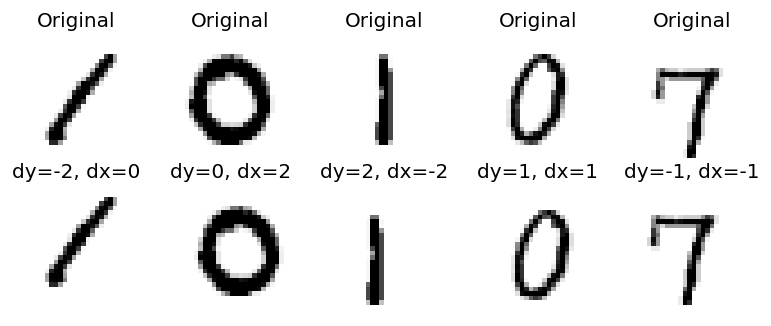

In [3]:
def shift_images(images, offsets):
    shifted = np.zeros_like(images)
    for dy, dx in np.unique(offsets, axis=0):
        selected = (offsets[:, 0] == dy) & (offsets[:, 1] == dx)
        y0, y1 = max(0, -dy), min(28, 28 - dy)
        x0, x1 = max(0, -dx), min(28, 28 - dx)
        shifted[selected, y0 + dy:y1 + dy, x0 + dx:x1 + dx] = images[selected, y0:y1, x0:x1]
    return shifted

shift_rng = np.random.default_rng(training["validation_shift_seed"])
val_offsets = shift_rng.integers(
    -training["max_shift"], training["max_shift"] + 1, size=(len(val_indices), 2)
)
shifted_val_pixels = shift_images(pixels[val_indices].reshape(-1, 28, 28), val_offsets).reshape(-1, 784)
X_val_shifted = shifted_val_pixels.astype(np.float32) / 255.0

sample = X_train[:5].reshape(-1, 28, 28)
example_offsets = np.array([[-2, 0], [0, 2], [2, -2], [1, 1], [-1, -1]])
examples_shifted = shift_images(sample, example_offsets)
fig, axes = plt.subplots(2, 5, figsize=(8, 3))
for i in range(5):
    axes[0, i].imshow(sample[i], cmap="gray_r", vmin=0, vmax=1)
    axes[1, i].imshow(examples_shifted[i], cmap="gray_r", vmin=0, vmax=1)
    axes[0, i].set_title("Original")
    axes[1, i].set_title(f"dy={example_offsets[i, 0]}, dx={example_offsets[i, 1]}")
    axes[0, i].axis("off")
    axes[1, i].axis("off")

## Baseline

In [6]:
def score_predictions(labels, predicted):
    return {
        "accuracy": float(accuracy_score(labels, predicted)),
        "macro_f1": float(f1_score(labels, predicted, average="macro", zero_division=0)),
    }

baseline_config = baseline_run["config"]
baseline = LogisticRegression(
    **baseline_config["model"], penalty="l2", random_state=baseline_config["experiment"]["seed"]
)
started = time.perf_counter()
with threadpool_limits(limits=training["threads"]):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        baseline.fit(pixels[train_indices].astype(np.float64) / 255.0, y_train)
    baseline_seconds = time.perf_counter() - started
    baseline_prob = baseline.predict_proba(pixels[val_indices].astype(np.float64) / 255.0)
    baseline_shifted_prob = baseline.predict_proba(shifted_val_pixels.astype(np.float64) / 255.0)

if any(issubclass(w.category, ConvergenceWarning) for w in caught):
    raise RuntimeError("Логрег не сошёлся")

baseline_pred = baseline_prob.argmax(axis=1)
baseline_metrics = score_predictions(y_val, baseline_pred)
baseline_metrics.update({f"shifted_{key}": value for key, value in
                         score_predictions(y_val, baseline_shifted_prob.argmax(axis=1)).items()})
baseline_metrics

{'accuracy': 0.9133333333333333,
 'macro_f1': 0.9121390412928904,
 'shifted_accuracy': 0.643095238095238,
 'shifted_macro_f1': 0.644204214030404}

## Обучение MLP

784 -> 128 -> 10, Adam, L2

In [ ]:
def train_mlp(experiment, seed):
    model = MLPClassifier(
        hidden_layer_sizes=(training["hidden_units"],), activation=experiment["activation"],
        solver="adam", alpha=training["alpha"], batch_size=training["batch_size"],
        learning_rate_init=training["learning_rate"], shuffle=False, random_state=seed,
        early_stopping=False,
    )

    order_rng = np.random.default_rng(seed)
    augmentation_rng = np.random.default_rng(seed + 1000)
    history = []
    total_seconds = 0.0

    for epoch in range(1, training["epochs"] + 1):
        started = time.perf_counter()
        order = order_rng.permutation(len(y_train))
        epoch_data = X_train

        if experiment["augmentation"]:
            offsets = augmentation_rng.integers(
                -training["max_shift"], training["max_shift"] + 1, size=(len(y_train), 2)
            )
            epoch_data = shift_images(X_train.reshape(-1, 28, 28), offsets).reshape(-1, 784)

        with threadpool_limits(limits=training["threads"]):
            model.partial_fit(epoch_data[order], y_train[order], classes=np.arange(10))

        elapsed = time.perf_counter() - started
        total_seconds += elapsed
        with threadpool_limits(limits=training["threads"]):
            prob = model.predict_proba(X_val)

        val_metrics = score_predictions(y_val, prob.argmax(axis=1))
        row = {
            "experiment": experiment["name"], "seed": seed, "epoch": epoch,
            "train_loss": float(model.loss_), "val_loss": float(log_loss(y_val, prob, labels=np.arange(10))),
            "val_accuracy": val_metrics["accuracy"], "val_macro_f1": val_metrics["macro_f1"],
            "training_seconds": elapsed,
        }

        assert np.isfinite(list(val_metrics.values())).all() and np.isfinite(row["train_loss"])
        history.append(row)
        pd.DataFrame(history).to_csv(artifacts / f"history_{experiment['name']}_{seed}.csv", index=False)

        if epoch % 5 == 0:
            print(f"{experiment['name']}, seed {seed}, epoch {epoch}: {val_metrics['accuracy']:.4f}", flush=True)

    return model, history, total_seconds

In [8]:
def prediction_frame(name, seed, prob, shifted_prob):
    return pd.DataFrame({
        "experiment": name, "seed": seed, "row_index": val_indices, "true_label": y_val,
        "predicted_label": prob.argmax(axis=1), "confidence": prob.max(axis=1),
        "shifted_predicted_label": shifted_prob.argmax(axis=1),
        "shift_dy": val_offsets[:, 0], "shift_dx": val_offsets[:, 1],
    })

runs = [{
    "experiment": "logreg_hw1", "activation": "linear", "augmentation": False,
    "seed": baseline_config["experiment"]["seed"], "epochs": 0,
    "hypothesis": "Контрольный результат из ДЗ1", "training_seconds": baseline_seconds,
    "parameters": int(baseline.coef_.size + baseline.intercept_.size),
    **baseline_metrics,
}]
histories = []
predictions = [prediction_frame("logreg_hw1", runs[0]["seed"], baseline_prob, baseline_shifted_prob)]

for experiment in experiments:
    for seed in training["seeds"]:
        model, history, seconds = train_mlp(experiment, seed)
        with threadpool_limits(limits=training["threads"]):
            prob = model.predict_proba(X_val)
            shifted_prob = model.predict_proba(X_val_shifted)

        metrics = score_predictions(y_val, prob.argmax(axis=1))
        metrics.update({f"shifted_{key}": value for key, value in
                        score_predictions(y_val, shifted_prob.argmax(axis=1)).items()})

        parameter_count = sum(weights.size for weights in model.coefs_) + sum(bias.size for bias in model.intercepts_)
        runs.append({
            "experiment": experiment["name"], "activation": experiment["activation"],
            "augmentation": experiment["augmentation"], "hypothesis": experiment["hypothesis"],
            "seed": seed, "epochs": training["epochs"], "parameters": int(parameter_count),
            "training_seconds": seconds, **metrics,
        })

        histories.extend(history)
        predictions.append(prediction_frame(experiment["name"], seed, prob, shifted_prob))
        joblib.dump({
            "model": model, "experiment": experiment, "seed": seed, "config": config,
            "data_sha256": data_sha256, "split_sha256": split_sha256, "pixel_divisor": 255.0,
        }, artifacts / f"{experiment['name']}_{seed}.joblib", compress=3)
        pd.DataFrame(runs).to_csv(reports / "experiments.csv", index=False)
        pd.DataFrame(histories).to_csv(reports / "history.csv", index=False)
        pd.concat(predictions, ignore_index=True).to_csv(reports / "predictions.csv", index=False)
        print(f"Finished {experiment['name']}, seed {seed}, training {seconds:.1f} s", flush=True)

runs = pd.DataFrame(runs)
history = pd.DataFrame(histories)
predictions = pd.concat(predictions, ignore_index=True)

mlp_relu, seed 42, epoch 5: 0.9524
mlp_relu, seed 42, epoch 10: 0.9614
mlp_relu, seed 42, epoch 15: 0.9665
mlp_relu, seed 42, epoch 20: 0.9692
Finished mlp_relu, seed 42, training 1.8 s
mlp_relu, seed 43, epoch 5: 0.9540
mlp_relu, seed 43, epoch 10: 0.9685
mlp_relu, seed 43, epoch 15: 0.9688
mlp_relu, seed 43, epoch 20: 0.9705
Finished mlp_relu, seed 43, training 1.7 s
mlp_relu, seed 44, epoch 5: 0.9554
mlp_relu, seed 44, epoch 10: 0.9642
mlp_relu, seed 44, epoch 15: 0.9674
mlp_relu, seed 44, epoch 20: 0.9694
Finished mlp_relu, seed 44, training 1.7 s
mlp_relu_shift, seed 42, epoch 5: 0.9519
mlp_relu_shift, seed 42, epoch 10: 0.9649
mlp_relu_shift, seed 42, epoch 15: 0.9718
mlp_relu_shift, seed 42, epoch 20: 0.9730
Finished mlp_relu_shift, seed 42, training 2.5 s
mlp_relu_shift, seed 43, epoch 5: 0.9540
mlp_relu_shift, seed 43, epoch 10: 0.9667
mlp_relu_shift, seed 43, epoch 15: 0.9706
mlp_relu_shift, seed 43, epoch 20: 0.9736
Finished mlp_relu_shift, seed 43, training 2.6 s
mlp_relu_s

## Результаты

In [10]:
mlp_runs = runs[runs.experiment != "logreg_hw1"]
summary = mlp_runs.groupby("experiment", sort=False).agg(
    runs=("seed", "size"), accuracy=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    macro_f1=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    shifted_accuracy=("shifted_accuracy", "mean"), shifted_accuracy_std=("shifted_accuracy", "std"),
    shifted_macro_f1=("shifted_macro_f1", "mean"), training_seconds=("training_seconds", "mean"),
    parameters=("parameters", "first"),
)
summary.to_csv(reports / "summary.csv")

best_name = summary.accuracy.idxmax()
best_row = summary.loc[best_name]

print(f"Logreg: accuracy {baseline_metrics['accuracy']:.4f}, macro-F1 {baseline_metrics['macro_f1']:.4f}")
print(f"Best MLP: {best_name}, accuracy {best_row.accuracy:.4f} +- {best_row.accuracy_std:.4f}")

table = pd.DataFrame({
    "Accuracy": [f"{mean:.4f} +- {std:.4f}" for mean, std in zip(summary.accuracy, summary.accuracy_std)],
    "Macro-F1": [f"{mean:.4f} +- {std:.4f}" for mean, std in zip(summary.macro_f1, summary.macro_f1_std)],
    "Shifted accuracy": [f"{mean:.4f} +- {std:.4f}" for mean, std in zip(summary.shifted_accuracy, summary.shifted_accuracy_std)],
}, index=summary.index)
table.loc["logreg_hw1"] = [f"{baseline_metrics['accuracy']:.4f}", f"{baseline_metrics['macro_f1']:.4f}",
                           f"{baseline_metrics['shifted_accuracy']:.4f}"]
table.loc[["logreg_hw1", *summary.index]]

Logreg: accuracy 0.9133, macro-F1 0.9121
Best MLP: mlp_relu_shift, accuracy 0.9737 +- 0.0008


,Accuracy,Macro-F1,Shifted accuracy
experiment,,,
logreg_hw1,0.9133,0.9121,0.6431
mlp_relu,0.9697 +- 0.0007,0.9694 +- 0.0007,0.7533 +- 0.0055
mlp_relu_shift,0.9737 +- 0.0008,0.9736 +- 0.0009,0.9651 +- 0.0013
mlp_linear_shift,0.8688 +- 0.0035,0.8670 +- 0.0038,0.7884 +- 0.0029
mlp_linear,0.9179 +- 0.0011,0.9167 +- 0.0011,0.6424 +- 0.0028


## Ablation

Полный вариант — MLP с ReLU и сдвигами. Пробуем отключать сдвиги и ReLU

In [14]:
full = mlp_runs[mlp_runs.experiment == "mlp_relu_shift"].set_index("seed")
ablations = []
for component, name in [("augmentation", "mlp_relu"), ("relu", "mlp_linear_shift")]:
    reduced = mlp_runs[mlp_runs.experiment == name].set_index("seed")
    for seed in training["seeds"]:
        ablations.append({
            "component": component, "seed": seed,
            "accuracy_delta": full.loc[seed, "accuracy"] - reduced.loc[seed, "accuracy"],
            "macro_f1_delta": full.loc[seed, "macro_f1"] - reduced.loc[seed, "macro_f1"],
            "shifted_accuracy_delta": full.loc[seed, "shifted_accuracy"] - reduced.loc[seed, "shifted_accuracy"],
        })

ablations = pd.DataFrame(ablations)
ablations.to_csv(reports / "ablations.csv", index=False)

ablation_summary = ablations.groupby("component").agg(
    accuracy_delta=("accuracy_delta", "mean"), accuracy_delta_std=("accuracy_delta", "std"),
    macro_f1_delta=("macro_f1_delta", "mean"),
    shifted_accuracy_delta=("shifted_accuracy_delta", "mean"),
)
ablation_summary.round(4)

,accuracy_delta,accuracy_delta_std,macro_f1_delta,shifted_accuracy_delta
component,,,,
augmentation,0.0040,0.0011,0.0042,0.2118
relu,0.1049,0.0030,0.1066,0.1767


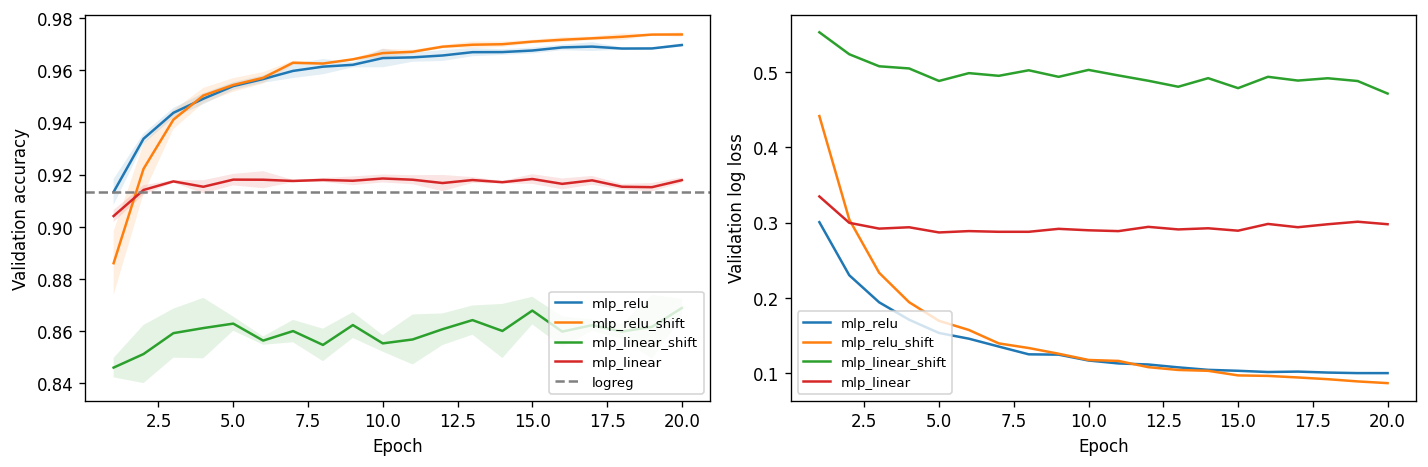

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, group in history.groupby("experiment", sort=False):
    curve = group.groupby("epoch").agg(
        accuracy=("val_accuracy", "mean"), std=("val_accuracy", "std"), loss=("val_loss", "mean")
    )
    axes[0].plot(curve.index, curve.accuracy, label=name)
    axes[0].fill_between(curve.index, curve.accuracy - curve["std"], curve.accuracy + curve["std"], alpha=0.12)
    axes[1].plot(curve.index, curve.loss, label=name)

axes[0].axhline(baseline_metrics["accuracy"], color="gray", linestyle="--", label="logreg")
axes[0].set(xlabel="Epoch", ylabel="Validation accuracy")
axes[1].set(xlabel="Epoch", ylabel="Validation log loss")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.tight_layout()

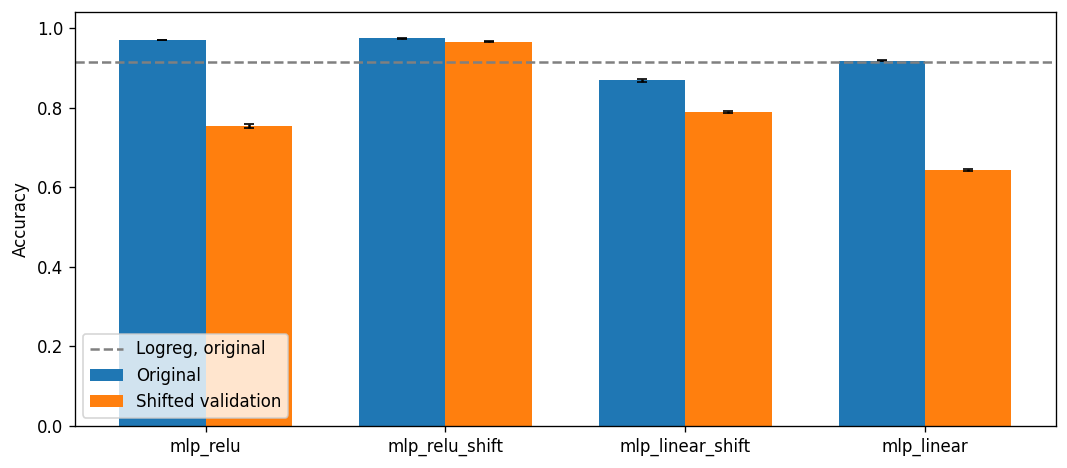

In [16]:
positions = np.arange(len(summary))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(positions - 0.18, summary.accuracy, 0.36, yerr=summary.accuracy_std, label="Original", capsize=3)
ax.bar(positions + 0.18, summary.shifted_accuracy, 0.36, yerr=summary.shifted_accuracy_std,
       label="Shifted validation", capsize=3)
ax.axhline(baseline_metrics["accuracy"], color="gray", linestyle="--", label="Logreg, original")
ax.set(xticks=positions, xticklabels=summary.index, ylabel="Accuracy", ylim=(0, 1.04))
ax.legend()
fig.tight_layout()

Видно что аугментация и ReLU полезы

## Ошибки

Разберем лучший вариант, сравним ошибки с logreg

Исправлено ошибок логрега: 555; новых ошибок: 54
 true  predicted  logreg_errors  mlp_errors
    4          9             41           6
    3          5             34          13
    5          3             32           9


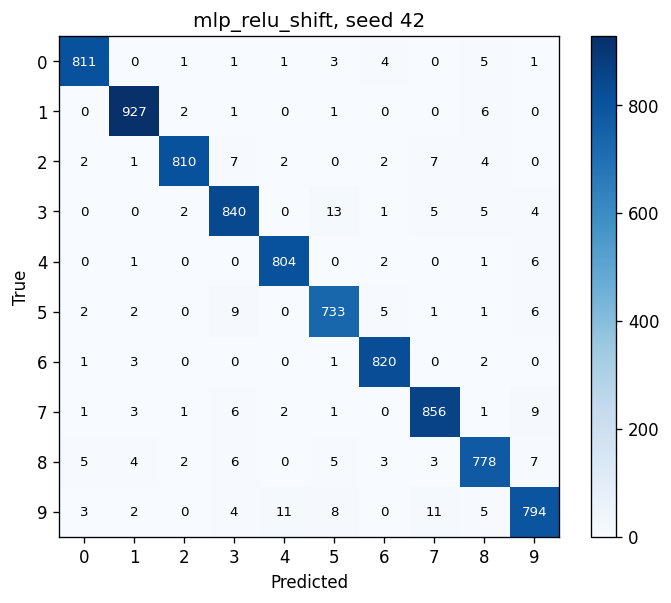

In [ ]:
representative_seed = training["seeds"][0]
representative = predictions[(predictions.experiment == best_name) & (predictions.seed == representative_seed)]
representative = representative.sort_values("row_index")
best_pred = representative.predicted_label.to_numpy()
corrected = (baseline_pred != y_val) & (best_pred == y_val)
introduced = (baseline_pred == y_val) & (best_pred != y_val)
print(f"Исправлено ошибок логрега: {corrected.sum()}; новых ошибок: {introduced.sum()}")
error_comparison = pd.DataFrame([
    {"true": i, "predicted": j,
     "logreg_errors": int(((y_val == i) & (baseline_pred == j)).sum()),
     "mlp_errors": int(((y_val == i) & (best_pred == j)).sum())}
    for i, j in [(4, 9), (3, 5), (5, 3)]
])

error_comparison.to_csv(reports / "error_comparison.csv", index=False)
print(error_comparison.to_string(index=False))
matrix = confusion_matrix(y_val, best_pred, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(matrix, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8,
                color="white" if matrix[i, j] > matrix.max() / 2 else "black")

ax.set(xticks=range(10), yticks=range(10), xlabel="Predicted", ylabel="True", title=f"{best_name}, seed {representative_seed}")
fig.colorbar(image, ax=ax)
fig.tight_layout()

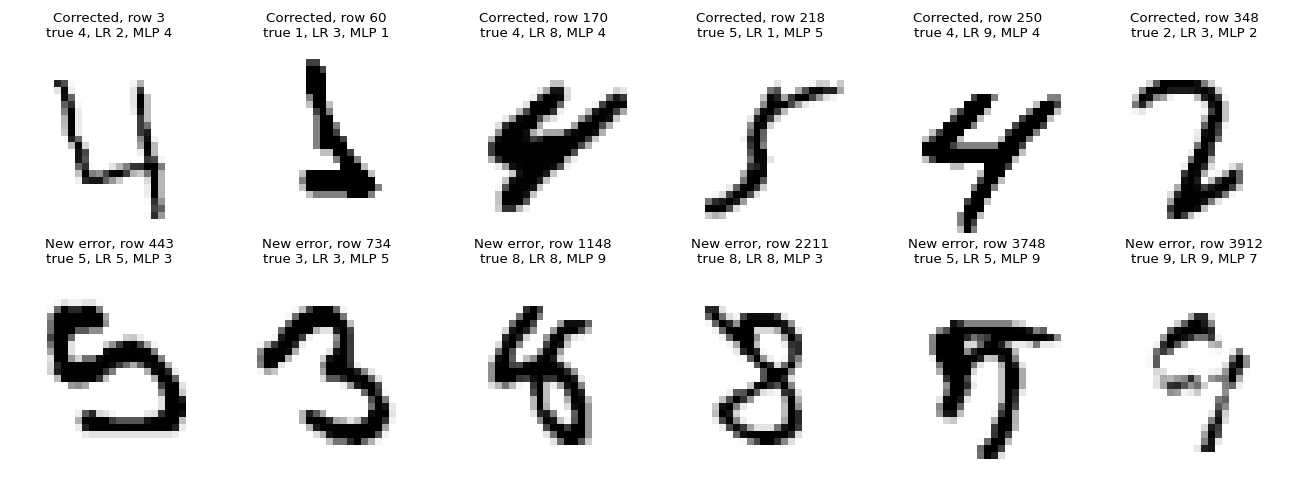

In [18]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for row, (mask, title) in enumerate([(corrected, "Corrected"), (introduced, "New error")]):
    selected = np.flatnonzero(mask)[:6]
    for ax in axes[row]:
        ax.axis("off")
    for ax, index in zip(axes[row], selected):
        ax.imshow(pixels[val_indices[index]].reshape(28, 28), cmap="gray_r", vmin=0, vmax=255)
        ax.set_title(f"{title}, row {val_indices[index]}\ntrue {y_val[index]}, LR {baseline_pred[index]}, MLP {best_pred[index]}", fontsize=8)
fig.tight_layout()

## Выводы

ReLU улучшила качество при одинаковом числе параметров и бюджете обучения.
Сдвиги помогли MLP с ReLU на исходной и сдвинутой validation во всех трёх запусках.
Выглядит так, что предсказания модели стали устойчивее, меньше реагировать на сдвиги

На линейной MLP сдвиги снизили исходную accuracy с 92% до 87%,
хотя устойчивость к сдвигу выросла. Наверно, линейной модели не хватает выразительности,
чтобы одновременно описывать такие варианты написания.

Количество ошибок на многих цифрах сократилось, но появились новые ошибки: например 5 → 3 и 3 → 5. 

Следующим экспериментом можно сравнить MLP с небольшой CNN.

In [19]:
print(f"Лучший вариант {best_name}: accuracy {best_row.accuracy:.4f} ± {best_row.accuracy_std:.4f}, "
      f"macro-F1 {best_row.macro_f1:.4f} ± {best_row.macro_f1_std:.4f}.")
print(f"Прирост к логрегу: {(best_row.accuracy - baseline_metrics['accuracy']) * 100:.2f} п.п.")
for component, row in ablation_summary.iterrows():
    print(f"Вклад {component}: исходная accuracy {row.accuracy_delta * 100:+.2f} п.п., "
          f"сдвинутая {row.shifted_accuracy_delta * 100:+.2f} п.п.")
print("Разброс рассчитан по трём сидам обучения на одном split. Значимость отдельно не оценивалась.")

Лучший вариант mlp_relu_shift: accuracy 0.9737 ± 0.0008, macro-F1 0.9736 ± 0.0009.
Прирост к логрегу: 6.04 п.п.
Вклад augmentation: исходная accuracy +0.40 п.п., сдвинутая +21.18 п.п.
Вклад relu: исходная accuracy +10.49 п.п., сдвинутая +17.67 п.п.
Разброс рассчитан по трём сидам обучения на одном split. Значимость отдельно не оценивалась.


In [20]:
manifest = {
    "config": config, "data_sha256": data_sha256, "split_sha256": split_sha256,
    "train_rows": len(train_indices), "validation_rows": len(val_indices),
    "baseline_metrics": baseline_metrics, "best_experiment": best_name,
    "selection_metric": "mean original validation accuracy at final epoch",
    "model_seeds": training["seeds"], "split_seed": baseline_config["experiment"]["seed"],
    "optimizer_steps_per_mlp": int(np.ceil(len(y_train) / training["batch_size"])) * training["epochs"],
    "training_examples_per_mlp": len(y_train) * training["epochs"],
    "validation_shift_seed": training["validation_shift_seed"],
    "representative_seed": representative_seed,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
}
(reports / "run.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + "\n")

2223